In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Генерируем датасет: 1000 клиентов, 20% отток (класс 1), 80% остаются (класс 0)
X_arr, y_arr = make_classification(
    n_samples=1000,
    n_features=5,
    n_informative=3,
    weights=[0.8, 0.2],
    random_state=42
)

# Переводим в DataFrame для удобства
X = pd.DataFrame(X_arr, columns=[f"Feature_{i}" for i in range(1, 6)])
y = pd.Series(y_arr, name="Churn")

print(f"Баланс классов:\n{y.value_counts(normalize=True)}")

Баланс классов:
Churn
0    0.802
1    0.198
Name: proportion, dtype: float64


In [5]:
# Разбиение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Создаем простейший пайплайн (масштабирование + регрессия)
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

# Обучение модели
pipeline.fit(X_train, y_train)

# Получаем ВЕРОЯТНОСТИ принадлежности к классу 1 (Отток)
y_proba = pipeline.predict_proba(X_test)[:, 1]

# Предсказания по умолчанию (порог 0.5)
y_pred_default = pipeline.predict(X_test)

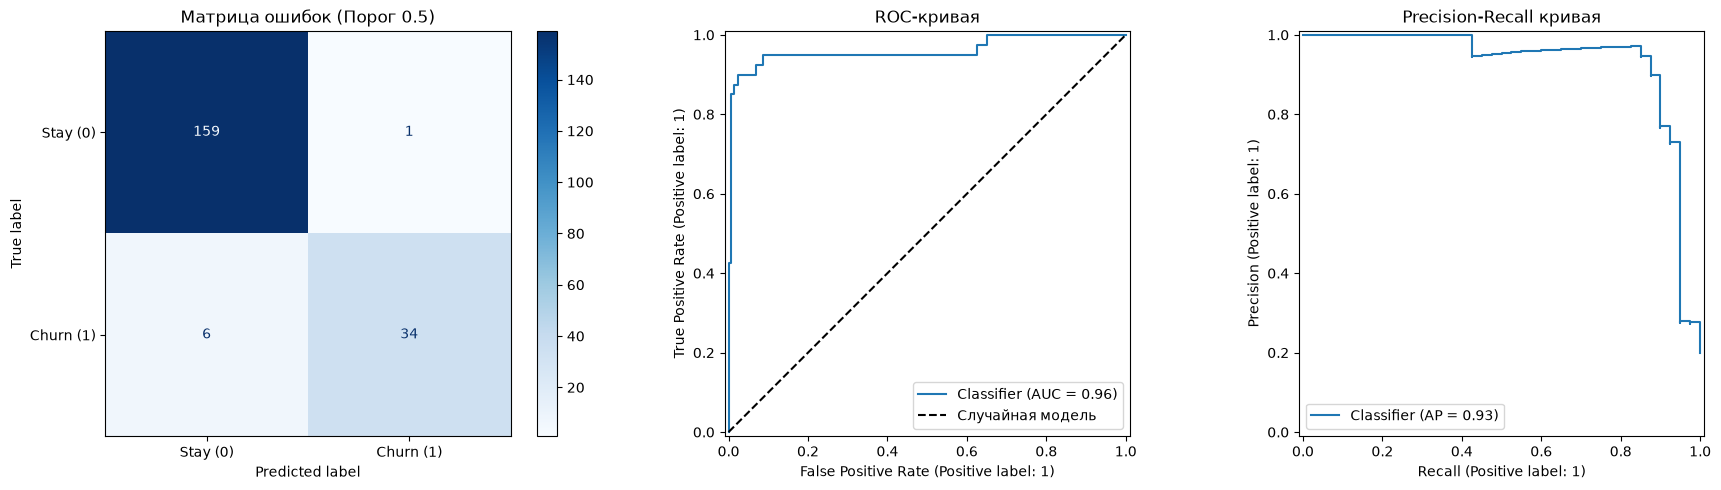

ROC-AUC Score: 0.961


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Матрица ошибок (порог 0.5)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_default, 
    display_labels=["Stay (0)", "Churn (1)"], 
    cmap="Blues", ax=axes[0]
)
axes[0].set_title("Матрица ошибок (Порог 0.5)")

# 2. ROC-кривая (убрали color)
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Случайная модель")
axes[1].set_title("ROC-кривая")
axes[1].legend()

# 3. PR-кривая (убрали color)
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[2].set_title("Precision-Recall кривая")

plt.tight_layout()
plt.show()

# Вычисление AUC
auc_score = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC Score: {auc_score:.3f}")

--- Метрики при пороге 0.5 (По умолчанию) ---
Accuracy:  0.965
Precision: 0.971 (доля реально ушедших среди предсказанных)
Recall:    0.850 (доля найденных ушедших от всех ушедших)
F1-score:  0.907

--- Метрики при пороге 0.3 (Адаптированный) ---
Accuracy:  0.940
Precision: 0.818 (доля реально ушедших среди предсказанных)
Recall:    0.900 (доля найденных ушедших от всех ушедших)
F1-score:  0.857



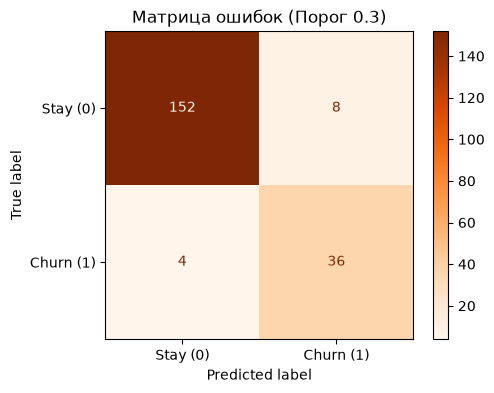

In [7]:
# Бизнес-логика: пропускать уход клиента (FN) очень дорого.
# Снижаем порог, чтобы модель чаще "била тревогу", если видит риск оттока.
custom_threshold = 0.3
y_pred_custom = (y_proba >= custom_threshold).astype(int)

# Функция для вывода метрик
def print_metrics(y_true, y_pred, threshold_name):
    print(f"--- Метрики при пороге {threshold_name} ---")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precision: {precision_score(y_true, y_pred):.3f} (доля реально ушедших среди предсказанных)")
    print(f"Recall:    {recall_score(y_true, y_pred):.3f} (доля найденных ушедших от всех ушедших)")
    print(f"F1-score:  {f1_score(y_true, y_pred):.3f}\n")

print_metrics(y_test, y_pred_default, "0.5 (По умолчанию)")
print_metrics(y_test, y_pred_custom, "0.3 (Адаптированный)")

# Построим новую матрицу ошибок для наглядности
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_custom, 
    display_labels=["Stay (0)", "Churn (1)"], 
    cmap="Oranges", ax=ax
)
plt.title("Матрица ошибок (Порог 0.3)")
plt.show()

### Выводы по классификатору:

1. **ROC-AUC (Площадь под ROC-кривой):** Значение AUC показывает способность модели отличать классы независимо от выбранного порога. В нашем случае AUC существенно выше 0.5, что говорит о хорошем качестве разделения классов.
2. **Анализ цены ошибки и выбор метрики:** В задаче прогнозирования оттока клиентов ложноотрицательное срабатывание (FN — не заметили клиента, и он ушел) обходится бизнесу дороже, чем ложноположительное (FP — дали скидку лояльному клиенту). Поэтому наиболее важной метрикой для нас является **Recall (Полнота)**.
3. **Обоснование порога:** 
   - При стандартном пороге `0.5` модель имеет высокий Precision, но упускает часть клиентов, склонных к оттоку (недостаточный Recall). 
   - Принудительно снизив порог до `0.3`, мы увеличили количество ложных срабатываний (упал Precision, выросли FP), но при этом **существенно повысили Recall**. Теперь мы «отлавливаем» больше рискованных клиентов, что математически выгоднее с точки зрения сохранения клиентской базы.